<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Air quality now: fine particles over Sweden 🌫️
### Copernicus Atmosphere Monitoring Service · European air-quality forecast · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/sweden/pm25_cams.ipynb)

The Copernicus Atmosphere Monitoring Service (CAMS), run by ECMWF for the European Union, forecasts air
quality across Europe every day, four days ahead, at about 10 km. This notebook takes the **latest forecast** of
**fine particulate matter (PM2.5)** near the ground, finds the hour with the dirtiest air over Sweden, maps it, and follows
five Swedish cities through the four days. The forecast is the median of eleven European air-quality models.

**What you need:** a Google account (to use Colab) and a free Copernicus account (next step). No fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [CAMS European air quality forecasts](https://ads.atmosphere.copernicus.eu/datasets/cams-europe-air-quality-forecasts), about 10 km | PM2.5 at the surface, ensemble median, the latest 00 UTC run, 3-hourly to +96 h | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to Sweden (SMHI, Norrköping), 2026. The visit graphic shows the run of 18 November 2026; this notebook always shows the newest run.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://ads.atmosphere.copernicus.eu/datasets/cams-europe-air-quality-forecasts?tab=download) on the Atmosphere Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np, shapely

## 1 · Choose the run and the area

In [4]:
now = dt.datetime.utcnow()
DATE = (now.date() if now.hour >= 12 else now.date() - dt.timedelta(days=1)).isoformat()   # the newest complete run
LEADS = list(range(0, 97, 3))                 # hours after 00 UTC, four days
AREA = [70.5, 4.0, 54.0, 32.0]                # north, west, south, east
PLACES = [("Stockholm", 59.329, 18.069), ("Norrköping", 58.588, 16.192), ("Gothenburg", 57.709, 11.975),
          ("Malmö", 55.605, 13.004), ("Luleå", 65.584, 22.155)]

def label_places(chart, places):
    for name, la, lo in places:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the PM2.5 forecast from the Atmosphere Data Store

In [5]:
cams = ekd.from_source("ads", "cams-europe-air-quality-forecasts", {
    "variable": "particulate_matter_2.5um", "model": "ensemble", "level": "0", "type": "forecast",
    "date": f"{DATE}/{DATE}", "time": "00:00", "leadtime_hour": [str(h) for h in LEADS],
    "area": AREA, "data_format": "grib"})
ds = cams.to_xarray(time_dims=["valid_time"])
pm = ds[list(ds.data_vars)[0]]
pm = pm.assign_coords(longitude=((pm.longitude + 180) % 360) - 180).sortby("longitude")
if float(pm.max()) < 1e-3:
    pm = pm * 1e9                             # kg/m³ -> µg/m³

# Sweden's outline (Natural Earth), to average over Swedish grid cells only
countries = shpreader.Reader(shpreader.natural_earth("50m", "cultural", "admin_0_countries")).records()
sweden = next(r.geometry for r in countries if r.attributes["ADMIN"] == "Sweden")
lon2, lat2 = np.meshgrid(pm.longitude.values, pm.latitude.values)
inside = shapely.contains_xy(sweden, lon2, lat2)
swe = pm.where(inside).mean(["latitude", "longitude"])
worst = int(swe.argmax())
field = pm.isel(valid_time=worst)
valid = dt.datetime.fromisoformat(str(field.valid_time.values)[:19])
print(f"CAMS run {DATE} 00 UTC. Sweden mean PM2.5 {float(swe.min()):.1f} to {float(swe.max()):.1f} µg/m³; "
      f"highest {valid:%A %d %B %H}:00 UTC; highest single cell in Sweden {float(pm.where(inside).max()):.1f} µg/m³")

CAMS run 2026-11-22 00 UTC. Sweden mean PM2.5 0.7 to 1.2 µg/m³; highest Sunday 22 November 18:00 UTC; highest single cell in Sweden 6.3 µg/m³


## 3 · Map the dirtiest hour over Sweden

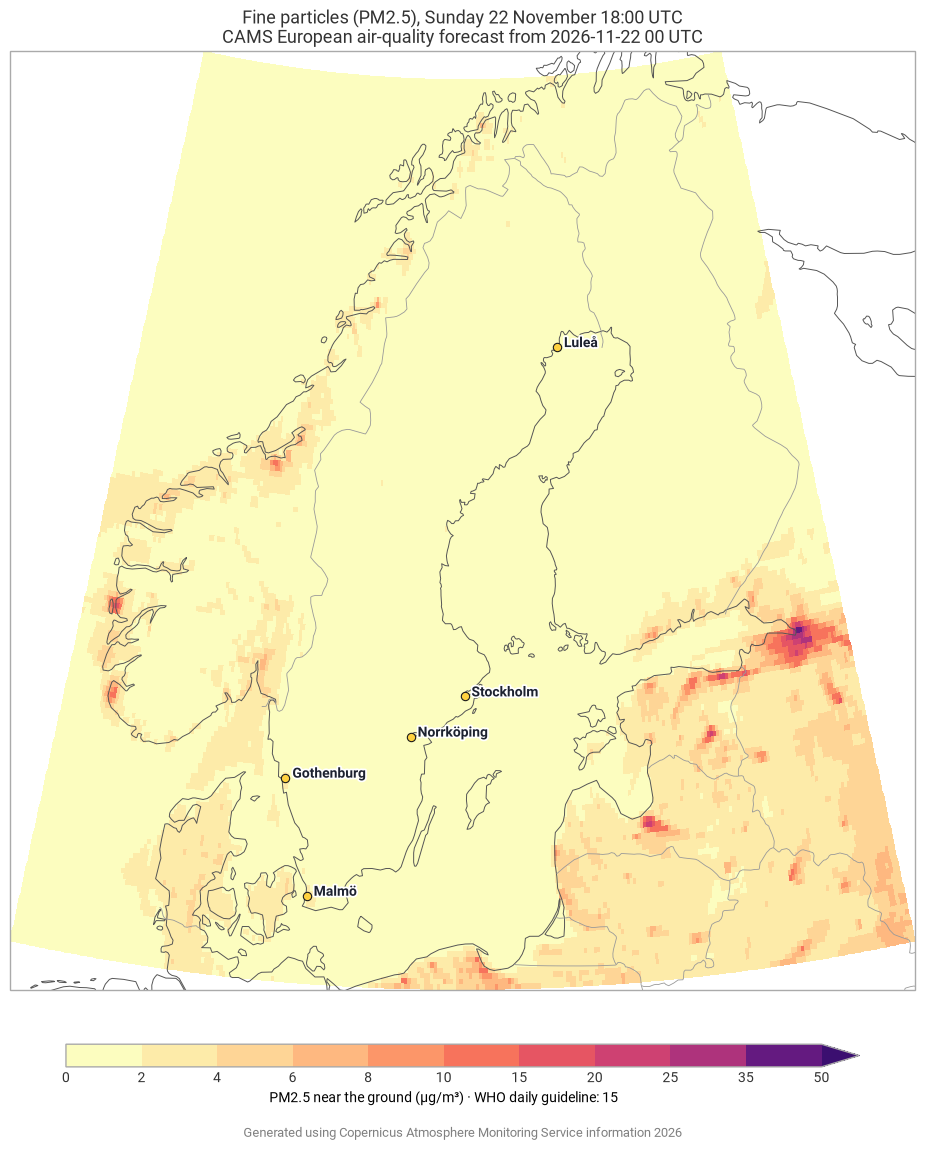

In [6]:
colors = ["#fcfdbf", "#fde7a3", "#fec98d", "#fd9f6c", "#f7735c", "#e24e65", "#c0397a", "#932b80", "#641a80", "#3b0f70"]
style = ekp.styles.Style(levels=[0, 2, 4, 6, 8, 10, 15, 20, 25, 35, 50], colors=colors, extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(10, 11))
chart.pcolormesh(field, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
label_places(chart, PLACES)
chart.legend(label="PM2.5 near the ground (µg/m³) · WHO daily guideline: 15")
chart.title(f"Fine particles (PM2.5), {valid:%A %d %B %H}:00 UTC\nCAMS European air-quality forecast from {DATE} 00 UTC",
            fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("pm25_cams.png")
chart.show()

### Five cities through the four days

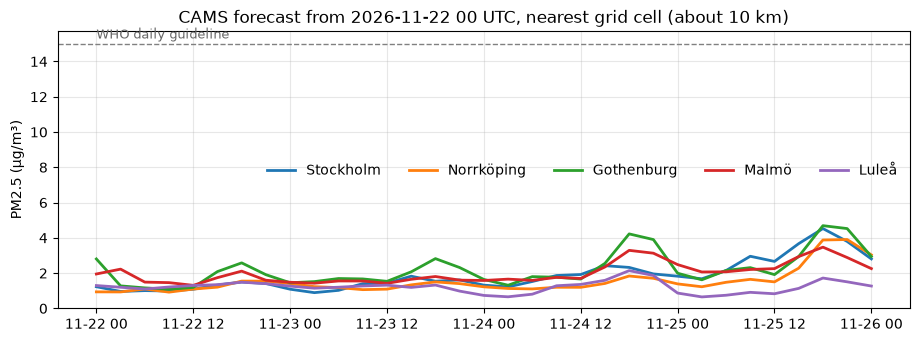

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for n, la, lo in PLACES:
    p = pm.sel(latitude=la, longitude=lo, method="nearest")
    ax.plot(p.valid_time, p, lw=2, label=n)
ax.axhline(15, color="0.5", ls="--", lw=1); ax.text(p.valid_time.values[0], 15.3, "WHO daily guideline", fontsize=9, color="0.4")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_ylim(bottom=0); ax.grid(alpha=0.3); ax.legend(frameon=False, ncol=5)
ax.set_title(f"CAMS forecast from {DATE} 00 UTC, nearest grid cell (about 10 km)")
plt.show()

## 4 · Your turn 🌍

- **Another hour:** set `worst` to any index into `LEADS` (0 = the start of the run) and re-run steps 2 and 3.
- **Another pollutant:** `"nitrogen_dioxide"` (traffic, cities), `"ozone"` (summer afternoons) or `"particulate_matter_10um"`.
- **A past forecast:** set `DATE` to any day of the last three years, for example a smoky summer day.
- **Your own area:** change `AREA` (the CAMS European domain stops at 72°N and 45°E) and the country name in step 2.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)